In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Leer el archivo generado por el Integrante 1
df = pd.read_csv("../datos/datos_tueste_cafe.csv")

print("Dimensiones del dataset:", df.shape)
display(df) 

Dimensiones del dataset: (12, 5)


,Etapa,Tiempo,Temperatura aproximada,tiempo_min,temperatura_C
0,Carga del café verde,0:00 min,100 °C,0.0,100.0
1,Inicio del secado,1:00 min,110 °C,1.0,110.0
2,Secado intermedio,2:00 min,126 °C,2.0,126.0
3,Secado avanzado,3:00 min,145 °C,3.0,145.0
4,Amarillamiento,4:00 min,155 °C,4.0,155.0
5,Transición a Maillard,5:00 min,165 °C,5.0,165.0
6,Inicio de Maillard,6:00 min,175 °C,6.0,175.0
7,Maillard avanzado,7:00 min,182 °C,7.0,182.0
8,Desarrollo de color,8:00 min,189 °C,8.0,189.0
9,Primer crack,9:00 min,196 °C,9.0,196.0


In [2]:
# Extraer arreglos numéricos
t = df["tiempo_min"].to_numpy(dtype=float)
T = df["temperatura_C"].to_numpy(dtype=float)
n = len(T)

# Confirmar paso uniforme dt = 1.0 min
dt = t[1] - t[0]
assert np.allclose(np.diff(t), dt), "El paso de tiempo dt no es uniforme."
print(f"Puntos totales: {n} | Paso uniforme dt = {dt} min")

# Inicializar arreglos para primera y segunda derivada
T_prima = np.zeros(n, dtype=float)
T_segunda = np.zeros(n, dtype=float)

# --- 1. Primera derivada T'(t) = dT/dt (Rate of Rise - RoR) ---
# Hacia adelante en el primer punto (t_0)
T_prima[0] = (T[1] - T[0]) / dt

# Centradas en los puntos interiores (t_1 ... t_10)
for i in range(1, n - 1):
    T_prima[i] = (T[i + 1] - T[i - 1]) / (2.0 * dt)

# Hacia atrás en el último punto (t_11)
T_prima[-1] = (T[-1] - T[-2]) / dt


# --- 2. Segunda derivada T''(t) = d²T/dt² ---
# Hacia adelante en el primer punto (t_0)
T_segunda[0] = (T[2] - 2.0 * T[1] + T[0]) / (dt ** 2)

# Centradas en los puntos interiores (t_1 ... t_10)
for i in range(1, n - 1):
    T_segunda[i] = (T[i + 1] - 2.0 * T[i] + T[i - 1]) / (dt ** 2)

# Hacia atrás en el último punto (t_11)
T_segunda[-1] = (T[-1] - 2.0 * T[-2] + T[-3]) / (dt ** 2)

Puntos totales: 12 | Paso uniforme dt = 1.0 min


In [3]:
# Construir DataFrame con las 5 columnas exactas requeridas
df_derivadas = pd.DataFrame({
    "Etapa": df["Etapa"],
    "tiempo_min": df["tiempo_min"],
    "temperatura_C": df["temperatura_C"],
    "RoR_T_prima": np.round(T_prima, 4),
    "T_segunda": np.round(T_segunda, 4)
})

# Guardar en CURVATURA_CAFE/datos/derivadas_tueste_cafe.csv
os.makedirs("../datos", exist_ok=True)
ruta_salida = "../datos/derivadas_tueste_cafe.csv"
df_derivadas.to_csv(ruta_salida, index=False, encoding="utf-8")

print("CSV guardado correctamente en:", ruta_salida)
display(df_derivadas)

CSV guardado correctamente en: ../datos/derivadas_tueste_cafe.csv


,Etapa,tiempo_min,temperatura_C,RoR_T_prima,T_segunda
0,Carga del café verde,0.0,100.0,10.0,6.0
1,Inicio del secado,1.0,110.0,13.0,6.0
2,Secado intermedio,2.0,126.0,17.5,3.0
3,Secado avanzado,3.0,145.0,14.5,-9.0
4,Amarillamiento,4.0,155.0,10.0,0.0
5,Transición a Maillard,5.0,165.0,10.0,0.0
6,Inicio de Maillard,6.0,175.0,8.5,-3.0
7,Maillard avanzado,7.0,182.0,7.0,0.0
8,Desarrollo de color,8.0,189.0,7.0,0.0
9,Primer crack,9.0,196.0,6.5,-1.0


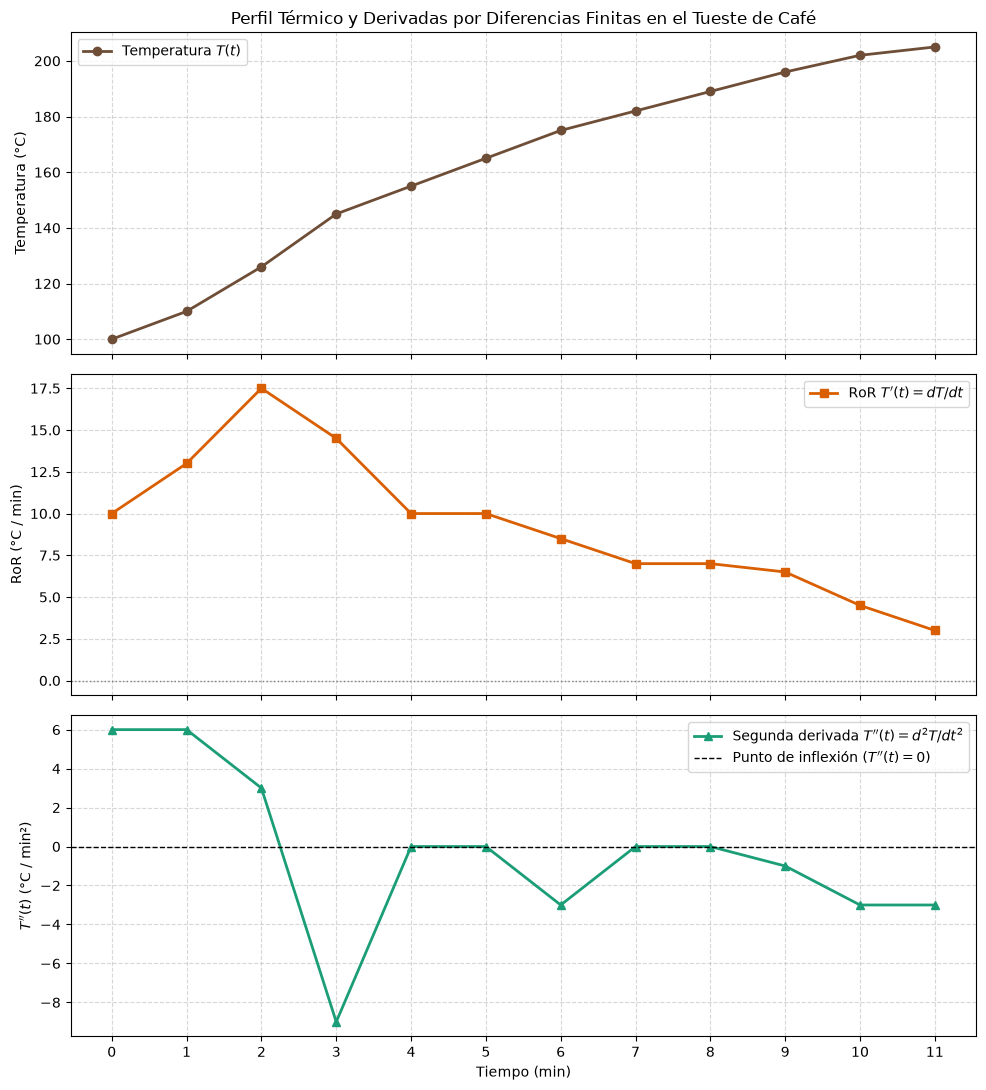

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)

# Gráfica 1: Temperatura T(t)
axes[0].plot(t, T, marker="o", color="#6F4E37", linewidth=2, label="Temperatura $T(t)$")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].set_title("Perfil Térmico y Derivadas por Diferencias Finitas en el Tueste de Café")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper left")

# Gráfica 2: Primera derivada T'(t) - Rate of Rise (RoR)
axes[1].plot(t, T_prima, marker="s", color="#D95F02", linewidth=2, label="RoR $T'(t) = dT/dt$")
axes[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axes[1].set_ylabel("RoR (°C / min)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(loc="upper right")

# Gráfica 3: Segunda derivada T''(t) - Puntos de inflexión
axes[2].plot(t, T_segunda, marker="^", color="#1B9E77", linewidth=2, label="Segunda derivada $T''(t) = d^2T/dt^2$")
axes[2].axhline(0, color="black", linestyle="--", linewidth=1, label="Punto de inflexión ($T''(t) = 0$)")
axes[2].set_xlabel("Tiempo (min)")
axes[2].set_ylabel("$T''(t)$ (°C / min²)")
axes[2].set_xticks(t)
axes[2].grid(True, linestyle="--", alpha=0.5)
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()